In [3]:
!pip install -U scikit-learn
!pip install PyTDC --no-deps #tdc did not want to work in the google collab session otherwise
!pip install fuzzywuzzy

In [4]:
!pip install rdkit deepchem

In [5]:
import rdkit
import deepchem

print(rdkit.__version__)
print(deepchem.__version__)

No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading modules with pytorch-geometric dependency, missing a dependency. No module named 'torch_geometric'
Skipped loading modules with pytorch-geometric dependency, missing a dependency. cannot import name 'DMPNN' from 'deepchem.models.torch_models' (/opt/anaconda3/envs/cheminfo/lib/python3.11/site-packages/deepchem/models/torch_models/__init__.py)
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'jax'
Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


2023.09.6
2.8.0


### Load data and exploration

In [6]:
from tdc.single_pred import Tox

data = Tox(name='hERG_Karim')
df_raw = data.get_data()
print(df_raw.shape)
df_raw.head()

Found local copy...
Loading...
Done!


(13445, 3)


,Drug_ID,Drug,Y
0,0,Fc1ccc(-n2cc(NCCN3CCCCC3)nn2)cc1F,1
1,1,COc1cc(N2Cc3ccc(Sc4ccc(F)cc4)nc3C2=O)ccc1OCCN1...,0
2,2,CCOC(=O)[C@H]1CC[C@@H](N2CC(NC(=O)CNc3nn(C(N)=...,0
3,3,N[C@@H](Cn1c(=O)cnc2ccc(F)cc21)C1CCC(NCc2ccc3c...,0
4,4,O=C(NC1COc2cccc(-c3ccnc(CO)c3)c2C1)c1ccc(OCC(F...,0


In [7]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13445 entries, 0 to 13444
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Drug_ID  13445 non-null  int64 
 1   Drug     13445 non-null  object
 2   Y        13445 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 315.2+ KB


In [8]:
df_raw['Y'].value_counts(normalize=True)

Y
0    0.500335
1    0.499665
Name: proportion, dtype: float64

In [9]:
df = df_raw.drop(columns=['Drug_ID']).copy()
df.head()

,Drug,Y
0,Fc1ccc(-n2cc(NCCN3CCCCC3)nn2)cc1F,1
1,COc1cc(N2Cc3ccc(Sc4ccc(F)cc4)nc3C2=O)ccc1OCCN1...,0
2,CCOC(=O)[C@H]1CC[C@@H](N2CC(NC(=O)CNc3nn(C(N)=...,0
3,N[C@@H](Cn1c(=O)cnc2ccc(F)cc21)C1CCC(NCc2ccc3c...,0
4,O=C(NC1COc2cccc(-c3ccnc(CO)c3)c2C1)c1ccc(OCC(F...,0


The dataset has 3 columns: Drug_ID, Drug (a SMILES string) and a binary target label Y. Target indicates whether the molecule blocks the hERG potassium channel (Y=1,IC50 < 10µM) or not (Y=0, IC50 >= 10 µM). Drug_ID column was removed, because it does not contain
 useful information for prediction.

The dataset contains 13 445 molecules with no missing values and classes are well-balanced.

In [10]:
# Scaffold split (70% train, 15% validation, 15% test)
split = data.get_split(method='scaffold', frac=[0.7, 0.15, 0.15], seed=42)

train_df = split['train']
val_df = split['valid']
test_df = split['test']


y_train = train_df['Y'].values
y_val = val_df['Y'].values
y_test = test_df['Y'].values

print("Training set:", train_df.shape)
print("Validation set:", val_df.shape)
print("Test set:", test_df.shape)


100%|██████████| 13445/13445 [00:05<00:00, 2494.63it/s]


Training set: (9411, 3)
Validation set: (2016, 3)
Test set: (2018, 3)


### Featurization

Each SMILES string is converted into numerical feature vector using RDKit descriptor featurizer, which calculates a set of descriptors, 210 odf them, per molecule

In [11]:
from deepchem.feat import RDKitDescriptors

featurizer = RDKitDescriptors()

Xtr = featurizer.featurize(train_df['Drug'].tolist())   # train
Xva = featurizer.featurize(val_df['Drug'].tolist())     # val
Xte = featurizer.featurize(test_df['Drug'].tolist())    # test

In [12]:
print(f"Number of generated molecular descriptors: {Xtr.shape[1]}")

Number of generated molecular descriptors: 210


We need to check the descriptors for invalid vales, infinity values are converted to NaN and any descriptor with invalid values is removed. After that we remove zero variance descriptors, since they carry no information. This reduces the number of features to 198

In [13]:
import numpy as np

Xtr = np.where(np.isinf(Xtr), np.nan, Xtr)
valid_cols = ~np.isnan(Xtr).any(axis=0)

Xtr = Xtr[:, valid_cols]
Xva = np.where(np.isinf(Xva), np.nan, Xva)[:, valid_cols]
Xte = np.where(np.isinf(Xte), np.nan, Xte)[:, valid_cols]

print(f"Number of molecular descriptors without invalid values: {Xtr.shape[1]}")

Number of molecular descriptors without invalid values: 198


In [14]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.0)
Xtr = selector.fit_transform(Xtr)
Xva = selector.transform(Xva)
Xte = selector.transform(Xte)

print(f"Number of features after removing zero-variance features: {Xtr.shape[1]}")

Number of features after removing zero-variance features: 190


The features are standardized with StandardScaler, which was fitted on the training set and applied to the validation and test sets

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xtr_s = scaler.fit_transform(Xtr)
Xva_s = scaler.transform(Xva)
Xte_s = scaler.transform(Xte)

print("Scaled train: ", Xtr_s.shape)
print("Scaled val: ", Xva_s.shape)
print("Scaled test: ", Xte_s.shape)

Scaled train:  (9411, 190)
Scaled val:  (2016, 190)
Scaled test:  (2018, 190)


For feature selection we use L1 regularized logistic regression, which penalizes large coefficients and sets coefficients corresponding to least informative features to 0 (and makes sense with high-dimensional datasets). Only selected descriptors, 123 of them, are kept.

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectFromModel

l1 = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42)
selector_l1 = SelectFromModel(l1)

selector_l1.fit(Xtr_s, y_train)

Xtr_sel = selector_l1.transform(Xtr_s)
Xva_sel = selector_l1.transform(Xva_s)
Xte_sel = selector_l1.transform(Xte_s)

print(f"Features selected by L1: {Xtr_sel.shape[1]} / {Xtr_s.shape[1]}")

Features selected by L1: 123 / 190


### RF and SVM models

RANDOM FOREST

Hyperparameters are tuned with 5 fold cross validation on the training set, optimizing ROC AUC, and the best configuration is evaluated on the validation set.

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_grid = {
    'n_estimators':      [100, 150, 200, 250],
    'max_depth':         [None, 10, 20, 30],
    'max_features':      ['sqrt', 'log2', 0.5],
    'min_samples_leaf':  [1, 2, 5],
}

rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_search = GridSearchCV(rf, rf_grid, scoring='roc_auc', cv=5, n_jobs=-1, verbose=1)
rf_search.fit(Xtr_sel, y_train)

print("RF best params:", rf_search.best_params_)
print(f"RF best CV ROC-AUC: {rf_search.best_score_:.3f}")
best_rf = rf_search.best_estimator_

Fitting 5 folds for each of 144 candidates, totalling 720 fits


/opt/anaconda3/envs/cheminfo/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/opt/anaconda3/envs/cheminfo/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/opt/anaconda3/envs/cheminfo/lib/python3.11/multiprocessing/queues.py:122: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or

RF best params: {'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 1, 'n_estimators': 250}
RF best CV ROC-AUC: 0.841


In [18]:
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score,
                             matthews_corrcoef, classification_report, confusion_matrix)

y_val_pred  = best_rf.predict(Xva_sel)
y_val_proba = best_rf.predict_proba(Xva_sel)[:, 1]

print("Tuned Random Forest — validation performance")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_val, y_val_proba):.3f}")
print(f"F1: {f1_score(y_val, y_val_pred):.3f}")
print(f"MCC: {matthews_corrcoef(y_val, y_val_pred):.3f}")

Tuned Random Forest — validation performance
Accuracy: 0.759
ROC-AUC: 0.841
F1: 0.753
MCC: 0.522


SUPPORT VECTOR MACHINE

SVM separates classes with the widest possible margin using RBF kernel to capture non linear boundaries. C and gamma patameters are tuned by 5 fold cross validation on training set.

In [20]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svm_grid = {
    'C':     [0.1, 1, 10],
    'gamma': ['scale', 0.01, 0.1],
}

svm = SVC(kernel='rbf', probability=True, random_state=42)
svm_search = GridSearchCV(svm, svm_grid, scoring='roc_auc', cv=5, n_jobs=1, verbose=1)  # n_jobs=1
svm_search.fit(Xtr_sel, y_train)

print("SVM best params:", svm_search.best_params_)
print(f"SVM best CV ROC-AUC: {svm_search.best_score_:.3f}")
best_svm = svm_search.best_estimator_

Fitting 5 folds for each of 9 candidates, totalling 45 fits
SVM best params: {'C': 10, 'gamma': 'scale'}
SVM best CV ROC-AUC: 0.831


In [21]:
y_val_pred  = best_svm.predict(Xva_sel)
y_val_proba = best_svm.predict_proba(Xva_sel)[:, 1]

print("Tuned SVM — validation performance")
print(f"Accuracy: {accuracy_score(y_val, y_val_pred):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_val, y_val_proba):.3f}")
print(f"F1: {f1_score(y_val, y_val_pred):.3f}")
print(f"MCC: {matthews_corrcoef(y_val, y_val_pred):.3f}")


Tuned SVM — validation performance
Accuracy: 0.760
ROC-AUC: 0.829
F1: 0.758
MCC: 0.522


Random forest and SVM show comparable performance in terms of accuracy, and RF has a slightly better ROC-AUC. Will try boosting models now and add Morgan fingerprints featurization approach.

To compare all classification models on the same basis, the tuned Random Forest and SVM were also evaluated on the test set, so that their results can be compared directly with the boosting models.

In [22]:
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, matthews_corrcoef

for name, model in [('Random Forest', best_rf), ('SVM', best_svm)]:
    y_test_pred  = model.predict(Xte_sel)
    y_test_proba = model.predict_proba(Xte_sel)[:, 1]
    print(f"{name} — test")
    print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.3f}")
    print(f"ROC-AUC: {roc_auc_score(y_test, y_test_proba):.3f}")
    print(f"F1: {f1_score(y_test, y_test_pred):.3f}")
    print(f"MCC: {matthews_corrcoef(y_test, y_test_pred):.3f}")

Random Forest — test
Accuracy: 0.802
ROC-AUC: 0.877
F1: 0.798
MCC: 0.603
SVM — test
Accuracy: 0.790
ROC-AUC: 0.861
F1: 0.790
MCC: 0.581


## Boosting models

In [ ]:
!pip install catboost xgboost

In [ ]:
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from tqdm.notebook import tqdm

### Default params + adding Morgan fp as the second featurization approach

In [ ]:
# we already have descriptors from experiments above, will generate Morgan fingerprints here in the same manner
from rdkit.Chem import rdFingerprintGenerator
from rdkit import Chem

mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

#get smiles from original data]
smi_train = train_df['Drug'].tolist()
smi_val = val_df['Drug'].tolist()
smi_test = test_df['Drug'].tolist()

def morgan_array(smiles):
    return np.array([mfpgen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in smiles])

Xtr_mor = morgan_array(smi_train)
Xva_mor = morgan_array(smi_val)
Xte_mor = morgan_array(smi_test)

#feature selection w l1
l1_mor = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42)
selector_mor = SelectFromModel(l1_mor)
selector_mor.fit(Xtr_mor, y_train)

Xtr_morsel = selector_mor.transform(Xtr_mor)
Xva_morsel = selector_mor.transform(Xva_mor)
Xte_morsel = selector_mor.transform(Xte_mor)

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, f1_score

feature_sets = {
    'rdkit_l1': (Xtr_sel, Xva_sel, Xte_sel),
    'morgan_l1': (Xtr_morsel, Xva_morsel, Xte_morsel),
}

def score(model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        'roc_auc': roc_auc_score(y, proba),
        'pr_auc': average_precision_score(y, proba),
        'accuracy': accuracy_score(y, pred),
        'f1': f1_score(y, pred),
    }

In [ ]:
import pandas as pd

rows = []
for feat_name, (Xa, Xb, Xc) in feature_sets.items():
    cat = CatBoostClassifier(random_seed=42, verbose=False)
    cat.fit(Xa, y_train)

    xgb = XGBClassifier(random_state=42)
    xgb.fit(Xa, y_train)

    for model_name, model in [('catboost', cat), ('xgboost', xgb)]:
        for split_name, X, y in [('val', Xb, y_val), ('test', Xc, y_test)]:
            rows.append({
                'features': feat_name,
                'model': model_name,
                'split': split_name,
                **score(model, X, y),
            })

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

 features    model split  roc_auc  pr_auc  accuracy    f1
 rdkit_l1 catboost   val    0.837   0.840     0.754 0.749
 rdkit_l1 catboost  test    0.875   0.865     0.800 0.795
 rdkit_l1  xgboost   val    0.802   0.808     0.737 0.738
 rdkit_l1  xgboost  test    0.861   0.853     0.798 0.794
morgan_l1 catboost   val    0.828   0.834     0.737 0.734
morgan_l1 catboost  test    0.856   0.864     0.759 0.752
morgan_l1  xgboost   val    0.817   0.823     0.747 0.748
morgan_l1  xgboost  test    0.858   0.863     0.771 0.769


Both featurization approaches have comparable metrics. Catboost performs better with descriptors, xgboost perform better with the fingerprints in terms of accuracy. Still, both with default hyperparams perform slightly worse than RF and SVM.

### Plotting loss and metrics

I want to look closer at how the training goes, so will plot loss and metrics behavior depending on the number of estimators.

In [ ]:
#helper function for plotting
import matplotlib.pyplot as plt

def plot_compare_estimators(estimator_labels, param_grid, train_metrics,
                            test_metrics, param_label='', metrics_label='',
                            title=''):

    plt.figure(figsize=(20, 7))

    for estimator_id in range(len(estimator_labels)):
        label = estimator_labels[estimator_id]
        plt.plot(
            param_grid, train_metrics[estimator_id],
            label=f'{label} train', linewidth=3
        )
        plt.plot(
            param_grid, test_metrics[estimator_id],
            label=f'{label} val', linewidth=3
        )

    plt.legend()
    plt.xlabel(param_label)
    plt.ylabel(metrics_label)
    plt.title(title, fontsize=20)

In [ ]:
from tqdm import tqdm
from sklearn.metrics import log_loss, roc_auc_score

n_estimators_grid = range(1, 300, 10)

#will use just training and validation for the plots
feature_sets = {
    'rdkit': (Xtr_sel, Xva_sel),
    'morgan': (Xtr_morsel, Xva_morsel),
}

In [ ]:
def run_curves(predict_fn, Xa, Xb):
    # predicts using the first k trees, so we have to only train once
    tr_loss, va_loss, tr_auc, va_auc = [], [], [], []
    for k in tqdm(n_estimators_grid):
        p_tr = predict_fn(Xa, k)
        p_va = predict_fn(Xb, k)
        tr_loss.append(log_loss(y_train, p_tr))
        va_loss.append(log_loss(y_val, p_va))
        tr_auc.append(roc_auc_score(y_train, p_tr))
        va_auc.append(roc_auc_score(y_val, p_va))
    return tr_loss, va_loss, tr_auc, va_auc

In [ ]:
results = {}

for feat_name, (Xa, Xb) in feature_sets.items():
    xgb = XGBClassifier(n_estimators=max(n_estimators_grid), random_state=42)
    xgb.fit(Xa, y_train)

    cat = CatBoostClassifier(iterations=max(n_estimators_grid), random_seed=42, verbose=False)
    cat.fit(Xa, y_train)

    results[f'XGBoost_{feat_name}'] = run_curves(
        lambda X, k, m=xgb: m.predict_proba(X, iteration_range=(0, k))[:, 1], Xa, Xb)

    results[f'CatBoost_{feat_name}'] = run_curves(
        lambda X, k, m=cat: m.predict_proba(X, ntree_end=k)[:, 1], Xa, Xb)

100%|██████████| 30/30 [00:02<00:00, 14.23it/s]


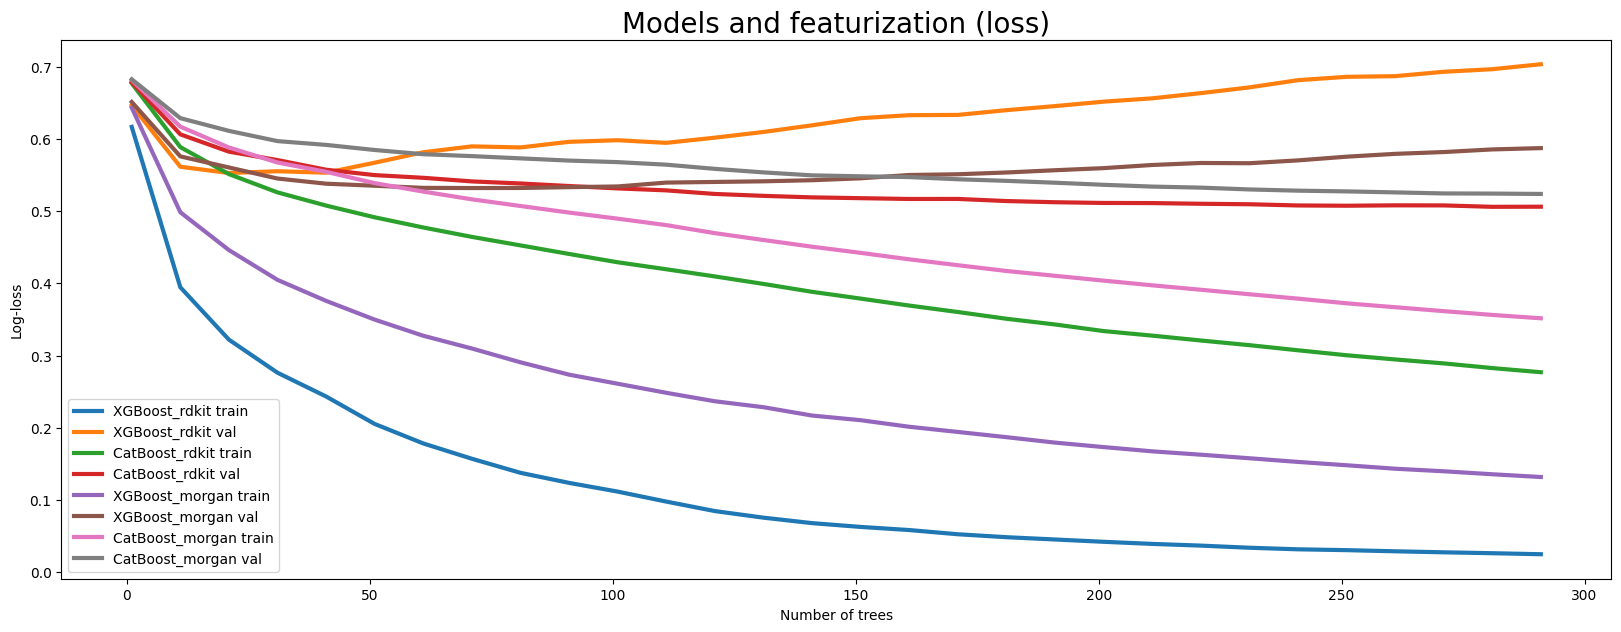

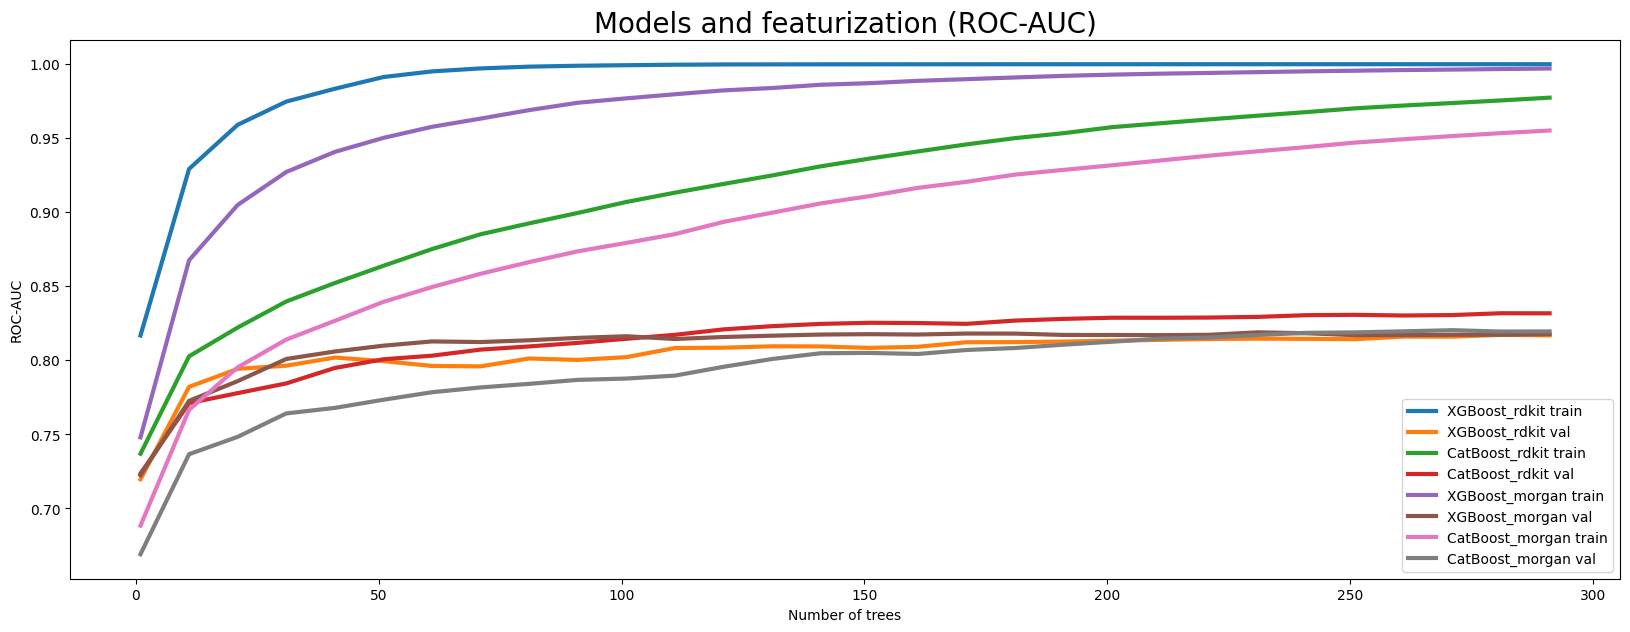

In [ ]:
labels = list(results.keys())
train_loss = [results[l][0] for l in labels]
val_loss = [results[l][1] for l in labels]
train_auc = [results[l][2] for l in labels]
val_auc = [results[l][3] for l in labels]

plot_compare_estimators(labels, n_estimators_grid, train_loss, val_loss,
                        'Number of trees', 'Log-loss',
                        'Models and featurization (loss)')

plot_compare_estimators(labels, n_estimators_grid, train_auc, val_auc,
                        'Number of trees', 'ROC-AUC',
                        'Models and featurization (ROC-AUC)')

In [ ]:
grid_list = list(n_estimators_grid)
for l in labels:
    best_k = grid_list[int(np.argmin(results[l][1]))]
    print(f"{l} (best val log-loss) = {best_k} trees")

XGBoost_rdkit (best val log-loss) = 21 trees
CatBoost_rdkit (best val log-loss) = 281 trees
XGBoost_morgan (best val log-loss) = 71 trees
CatBoost_morgan (best val log-loss) = 291 trees


Some of these losses look scary, models prone to overfitting. XGBoost has a large default learning rate and overfits quicker, Catboost tends to use more estimators, has built-in regularization.

### Feature selection and hyperparams optimization

Next I want to explore other feature selection approaches and include hyperparams optimization.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.feature_selection import SelectKBest, mutual_info_classif, SelectFromModel

# feature selection based on mutual information approach
mi = SelectKBest(mutual_info_classif, k=97)
mi.fit(Xtr_s, y_train)
Xtr_mi = mi.transform(Xtr_s)
Xva_mi = mi.transform(Xva_s)
Xte_mi = mi.transform(Xte_s)

# xgboost tree importance on rdkit descriptors
tree_sel = SelectFromModel(XGBClassifier(random_state=42), max_features=97)
tree_sel.fit(Xtr_s, y_train)
Xtr_tree = tree_sel.transform(Xtr_s)
Xva_tree = tree_sel.transform(Xva_s)
Xte_tree = tree_sel.transform(Xte_s)

# xgboost tree importance on morgan fp
morgan_tree = SelectFromModel(XGBClassifier(random_state=42), max_features=97)
morgan_tree.fit(Xtr_mor, y_train)
Xtr_mtree = morgan_tree.transform(Xtr_mor)
Xva_mtree = morgan_tree.transform(Xva_mor)
Xte_mtree = morgan_tree.transform(Xte_mor)

In [ ]:
feature_sets = {
    'rdkit_l1': (Xtr_sel, Xva_sel, Xte_sel),
    'rdkit_mi': (Xtr_mi, Xva_mi, Xte_mi),
    'rdkit_tree': (Xtr_tree, Xva_tree, Xte_tree),
    'morgan_l1': (Xtr_morsel, Xva_morsel, Xte_morsel),
    'morgan_tree': (Xtr_mtree, Xva_mtree, Xte_mtree),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# num of trees motivated by the plots above
xgb_trees = {
    'rdkit': [15, 21, 30],
    'morgan': [55, 71, 90],
}
cat_trees = {
    'rdkit': [200, 281, 350],
    'morgan': [250, 291, 400],
}

def get_grid(model_name, feat_type):
    if model_name == 'xgboost':
        return {
            'n_estimators': xgb_trees[feat_type],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.03, 0.1],
        }
    return {
        'iterations': cat_trees[feat_type],
        'depth': [4, 6, 8],
        'learning_rate': [0.03, 0.05, 0.1],
    }

In [ ]:
rows = []
final_models = {}

for feat_name, (Xa, Xb, Xc) in feature_sets.items():
    if feat_name.startswith('rdkit'):
        feat_type = 'rdkit'
    else:
        feat_type = 'morgan'

    # cv on train + validation
    X_trval = np.vstack([Xa, Xb])
    y_trval = np.concatenate([y_train, y_val])

    models = [
        ('xgboost', XGBClassifier(random_state=42)),
        ('catboost', CatBoostClassifier(random_seed=42, verbose=False)),
    ]

    for model_name, base_model in models:
        search = RandomizedSearchCV(
            base_model,
            param_distributions=get_grid(model_name, feat_type),
            n_iter=20,
            scoring='roc_auc',
            cv=cv,
            n_jobs=-1,
            random_state=42,
        )
        search.fit(X_trval, y_trval)

        final_models[(feat_name, model_name)] = search.best_estimator_

        s = score(search.best_estimator_, Xc, y_test)
        rows.append({
            'features': feat_name,
            'model': model_name,
            'cv_roc_auc': round(search.best_score_, 3),
            'test_roc_auc': round(s['roc_auc'], 3),
            'test_pr_auc': round(s['pr_auc'], 3),
            'test_acc': round(s['accuracy'], 3),
            'test_f1': round(s['f1'], 3),
            'best_params': search.best_params_,
        })
        print(f"{feat_name} {model_name} cv AUC={search.best_score_:.3f} {search.best_params_}")

rdkit_l1 xgboost cv AUC=0.875 {'n_estimators': 30, 'max_depth': 7, 'learning_rate': 0.1}
rdkit_l1 catboost cv AUC=0.913 {'learning_rate': 0.1, 'iterations': 281, 'depth': 8}
rdkit_mi xgboost cv AUC=0.877 {'n_estimators': 30, 'max_depth': 7, 'learning_rate': 0.1}
rdkit_mi catboost cv AUC=0.912 {'learning_rate': 0.1, 'iterations': 281, 'depth': 8}
rdkit_tree xgboost cv AUC=0.878 {'n_estimators': 30, 'max_depth': 7, 'learning_rate': 0.1}
rdkit_tree catboost cv AUC=0.911 {'learning_rate': 0.1, 'iterations': 281, 'depth': 8}
morgan_l1 xgboost cv AUC=0.875 {'n_estimators': 90, 'max_depth': 7, 'learning_rate': 0.1}
morgan_l1 catboost cv AUC=0.903 {'learning_rate': 0.1, 'iterations': 291, 'depth': 8}
morgan_tree xgboost cv AUC=0.830 {'n_estimators': 90, 'max_depth': 7, 'learning_rate': 0.1}
morgan_tree catboost cv AUC=0.850 {'learning_rate': 0.1, 'iterations': 291, 'depth': 8}


Results

In [ ]:
results_cv = pd.DataFrame(rows).sort_values('test_roc_auc', ascending=False)
results_cv.iloc[:, :-1]

,features,model,cv_roc_auc,test_roc_auc,test_pr_auc,test_acc,test_f1
3,rdkit_mi,catboost,0.912,0.882,0.880,0.809,0.806
1,rdkit_l1,catboost,0.913,0.879,0.874,0.798,0.796
5,rdkit_tree,catboost,0.911,0.879,0.875,0.801,0.803
7,morgan_l1,catboost,0.903,0.862,0.873,0.779,0.774
2,rdkit_mi,xgboost,0.877,0.855,0.837,0.780,0.775
0,rdkit_l1,xgboost,0.875,0.849,0.832,0.764,0.763
4,rdkit_tree,xgboost,0.878,0.849,0.832,0.774,0.771
6,morgan_l1,xgboost,0.875,0.844,0.849,0.754,0.746
9,morgan_tree,catboost,0.850,0.811,0.825,0.724,0.722
8,morgan_tree,xgboost,0.830,0.801,0.815,0.711,0.706


Confusion matrix and feature importance



In [ ]:
!pip install pycm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.4/610.4 kB 12.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pycm]


<Axes: title={'center': 'Confusion Matrix'}, xlabel='Predicted Classes', ylabel='Actual Classes'>

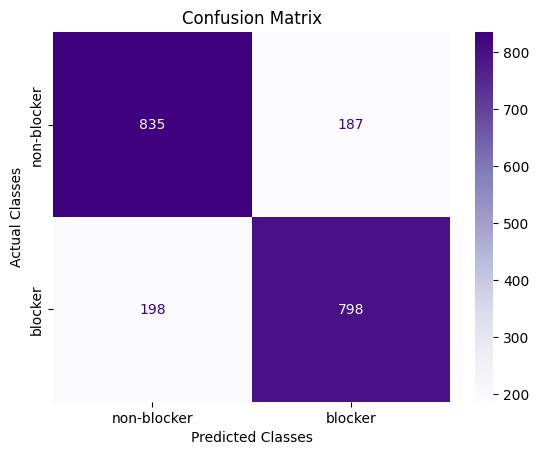

In [ ]:
from pycm import ConfusionMatrix

# best model from the cv
best_feat = results_cv.iloc[0]['features']
best_name = results_cv.iloc[0]['model']
final_model = final_models[(best_feat, best_name)]

Xc = feature_sets[best_feat][2]
y_pred = final_model.predict(Xc)

cm = ConfusionMatrix(actual_vector=y_test, predict_vector=y_pred)
cm.relabel(mapping={0: "non-blocker", 1: "blocker"})
cm.plot(cmap=plt.cm.Purples, number_label=True, plot_lib="seaborn")


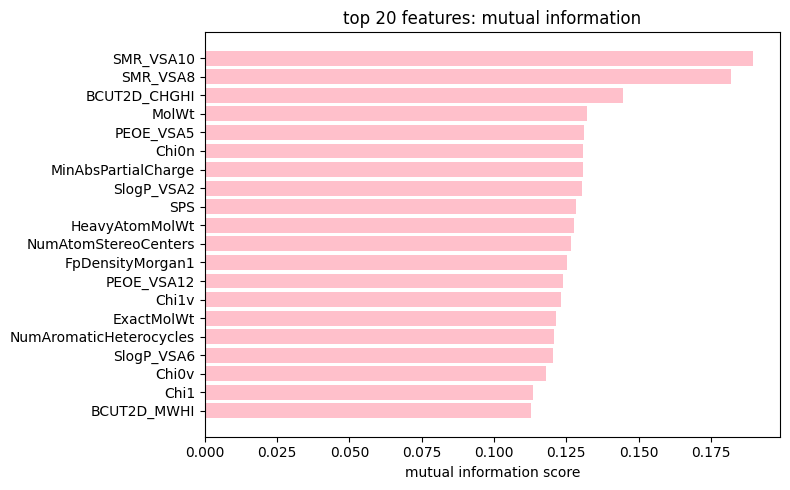

In [ ]:
mi_scores = mi.scores_
top = np.argsort(mi_scores)[::-1][:20]

plt.figure(figsize=(8, 5))
plt.barh([str(desc_names[i]) for i in top][::-1], mi_scores[top][::-1], color='pink')
plt.xlabel("mutual information score")
plt.title("top 20 features: mutual information")
plt.tight_layout()
plt.show()

From a high-level view, top features are size, surface area, or connectivity measures, which is common for hERG, where larger, more lipophilic molecules tend to block the channel more.